# 03. Back-end transport: mengirim data live ke dashboard

**Tujuan.** Membandingkan tiga cara mengirim paket EKG 1 detik dari server FastAPI ke browser: REST polling, Server-Sent Events (SSE), dan WebSocket. Yang diukur bukan hanya jeda, tetapi juga biaya sisi lain: bandwidth per klien dan pemakaian CPU server.

**Data.** Payload tiap paket adalah 250 sampel (1 detik, 250 Hz) dari rekaman MIT-BIH (notebook 00), dikonversi ke hitungan ADC 12 bit (asumsi 1 mV = 400 hitungan, TODO: cocokkan dengan kalibrasi AD8232 nyata) dan dikirim sebagai JSON.

**Konfigurasi.**
- `polling_1s`: klien meminta `/latest/{pid}` tiap 1 detik. Ini yang setara dengan laju paket.
- `polling_250ms`: polling tiap 250 ms. Ditambahkan karena polling 1 detik secara desain punya umur data rata-rata sekitar setengah detik. Polling lebih rapat menurunkan umur data, tetapi menaikkan biaya. Dengan begitu pembandingnya tidak hanya satu titik yang kebetulan merugikan polling.
- `sse`: `text/event-stream`, server mendorong tiap paket.
- `ws`: WebSocket, server mendorong tiap paket.

**Cara ukur.**
- Server berjalan sebagai proses terpisah (`uvicorn`, satu worker), dimulai baru untuk tiap pengukuran. Server mengirim paket tiap pasien sekali per detik dengan fase berbeda (perangkat tidak serempak).
- Klien berjalan di proses terpisah, maksimal 50 klien per proses, supaya klien tidak jadi penyempit.
- **Umur data** = waktu klien menerima paket dikurangi waktu server membuat paket (`t` dalam paket). Untuk push, itu jeda kirim. Untuk polling, itu juga mencakup waktu tunggu sampai poll berikutnya. Di sini satu jam dipakai bersama (satu mesin), jadi tidak ada galat sinkronisasi jam, tetapi uji ini tidak mewakili jaringan nyata.
- **Bandwidth per klien** = byte payload yang diterima klien per detik (header HTTP/WebSocket tidak dihitung, jadi angkanya batas bawah). Byte di tingkat jaringan (header TCP/IP) tidak diukur.
- **CPU server** = waktu CPU proses server (pengguna + sistem) dibagi waktu jam dinding selama jendela ukur, dalam persen dari satu inti.
- 3 detik pertama tiap pengukuran dibuang (pemanasan). Tiap kombinasi diulang 5 kali, urutan diacak (seed tetap). Median dengan IQR dan interval kepercayaan 95% bootstrap antar ulangan.

**Keterbatasan.**
- Satu mesin dan satu jam. Klien dan server berebut CPU yang sama. Uji di dua mesin dengan sinkronisasi NTP tidak dilakukan.
- Loopback tidak punya latensi jaringan, kehilangan paket, atau TLS. Biaya TLS, proxy, dan mobile data tidak terwakili.
- Alur perangkat ke server lewat MQTT tidak diuji, hanya server ke browser.

In [1]:
import sys, json, pathlib, subprocess, time, random, os, math, signal, socket
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, psutil, matplotlib.pyplot as plt, urllib.request
from bench import env, plotstyle, stats
from bench.plotstyle import ST
random.seed(0); np.random.seed(0)
QUICK = False
REPS, DUR, WARM = (2, 8, 2) if QUICK else (5, 15, 3)
NS = [1, 10, 50, 100, 200]
MODES = ["polling_1s", "polling_250ms", "sse", "ws"]
LABEL = {"polling_1s": "REST polling 1 s", "polling_250ms": "REST polling 250 ms", "sse": "SSE", "ws": "WebSocket"}
PER_PROC = 50; TD = ROOT/"bench/transport"; PY = sys.executable
e = env.info(["fastapi", "uvicorn", "aiohttp", "websockets"]); e.update(quick=QUICK, reps=REPS, dur_s=DUR, warm_s=WARM)
pd.Series(e, name="nilai").to_frame()

,nilai
cpu,Apple M2
inti_fisik,8
inti_logis,8
ram_gb,16.0
os,macOS-27.0.1-arm64-arm-64bit
python,3.11.15
fastapi,0.115.0
uvicorn,0.30.6
aiohttp,3.14.5
websockets,13.1


## 1. Jalankan benchmark

In [2]:
def free_port():
    with socket.socket() as s: s.bind(("127.0.0.1", 0)); return s.getsockname()[1]

def run_one(mode, n):
    port = free_port()
    srv = subprocess.Popen([PY, "-m", "uvicorn", "server:app", "--port", str(port), "--log-level", "warning"], cwd=TD,
                           stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    try:
        for _ in range(100):
            try: urllib.request.urlopen(f"http://127.0.0.1:{port}/latest/0", timeout=1); break
            except Exception: time.sleep(.1)
        time.sleep(1.5)  # server sudah memproduksi paket
        procs = []; left = n; p0 = 0
        while left > 0:
            k = min(PER_PROC, left)
            procs.append(subprocess.Popen([PY, "client.py", mode, str(port), str(p0), str(k), str(DUR), str(WARM)], cwd=TD,
                                          stdout=subprocess.PIPE, text=True)); p0 += k; left -= k
        ps = psutil.Process(srv.pid); time.sleep(WARM + .5)
        c0, t0 = sum(ps.cpu_times()[:2]), time.perf_counter()
        time.sleep(DUR - WARM - 1.5)
        c1, t1 = sum(ps.cpu_times()[:2]), time.perf_counter(); rss = ps.memory_info().rss / 2**20
        res = [json.loads(p.communicate(timeout=60)[0]) for p in procs]
    finally:
        srv.send_signal(signal.SIGTERM); srv.wait(10)
    lat = np.concatenate([r["lat"] for r in res]); win = DUR - WARM
    return {"mode": mode, "n": n, "paket": len(lat), "lat_median": np.median(lat), "lat_p95": np.percentile(lat, 95),
            "lat_p99": np.percentile(lat, 99), "kb_per_klien_s": sum(r["bytes"] for r in res) / n / win / 1024,
            "cpu_server_pct": 100 * (c1 - c0) / (t1 - t0), "rss_mb": rss,
            "redundan_pct": 100 * sum(r["redundant"] for r in res) / max(1, sum(r["polls"] for r in res))}

combos = [(m, n) for m in MODES for n in NS]; rows = []; t_start = time.time()
for rep in range(REPS):
    random.shuffle(combos)
    for m, n in combos:
        r = run_one(m, n); r["rep"] = rep; rows.append(r)
    print(f"ulangan {rep+1}/{REPS} selesai, {round(time.time()-t_start)} detik berlalu", flush=True)
raw = pd.DataFrame(rows); raw.to_csv(ROOT/"results/03_transport_raw.csv", index=False); len(raw)

ulangan 1/5 selesai, 365 detik berlalu


ulangan 2/5 selesai, 728 detik berlalu


ulangan 3/5 selesai, 1090 detik berlalu


ulangan 4/5 selesai, 1452 detik berlalu


ulangan 5/5 selesai, 1815 detik berlalu


100

## 2. Ringkasan

In [3]:
raw = pd.read_csv(ROOT/"results/03_transport_raw.csv"); rows = []
for (m, n), g in raw.groupby(["mode", "n"]):
    a = stats.summ(g.lat_median)
    rows.append({"konfigurasi": LABEL[m], "klien": n, "umur_median_ms": a["median"], "umur_iqr": f'{a["q1"]:.0f}-{a["q3"]:.0f}',
                 "umur_ci95": f'{a["ci_lo"]:.0f}-{a["ci_hi"]:.0f}', "p95_ms": g.lat_p95.median(), "p99_ms": g.lat_p99.median(),
                 "kb_per_klien_s": g.kb_per_klien_s.median(), "cpu_server_%": g.cpu_server_pct.median(), "rss_mb": g.rss_mb.median(),
                 "redundan_%": g["redundan_pct"].median(), "paket": int(g.paket.median())})
S = pd.DataFrame(rows); S.to_csv(ROOT/"results/03_transport_ringkasan.csv", index=False)
pd.set_option("display.width", 220); S.round(1)

,konfigurasi,klien,umur_median_ms,umur_iqr,umur_ci95,p95_ms,p99_ms,kb_per_klien_s,cpu_server_%,rss_mb,redundan_%,paket
0,REST polling 1 s,1,467.4,437-596,24-815,476.6,477.8,1.3,3.7,95.7,0.0,12
1,REST polling 1 s,10,424.2,387-493,370-536,917.7,925.3,1.2,5.4,95.8,0.0,115
2,REST polling 1 s,50,454.0,418-461,318-531,957.1,989.8,1.2,7.8,95.7,0.0,575
3,REST polling 1 s,100,523.0,467-530,368-553,969.2,992.7,1.2,8.3,95.7,0.0,1149
4,REST polling 1 s,200,484.9,485-494,380-521,941.6,992.5,1.2,12.2,95.8,0.0,2303
5,REST polling 250 ms,1,150.7,137-206,114-217,179.8,182.4,4.9,3.9,95.7,76.1,11
6,REST polling 250 ms,10,152.1,119-156,106-194,241.3,249.5,4.9,5.5,95.8,75.9,111
7,REST polling 250 ms,50,145.6,130-147,110-151,239.7,249.4,4.9,11.1,95.8,74.8,581
8,REST polling 250 ms,100,132.0,129-135,126-137,238.8,249.9,4.9,18.0,95.9,74.4,1180
9,REST polling 250 ms,200,121.4,121-125,116-133,240.4,250.0,4.9,30.3,78.7,74.9,2315


## 3. Grafik

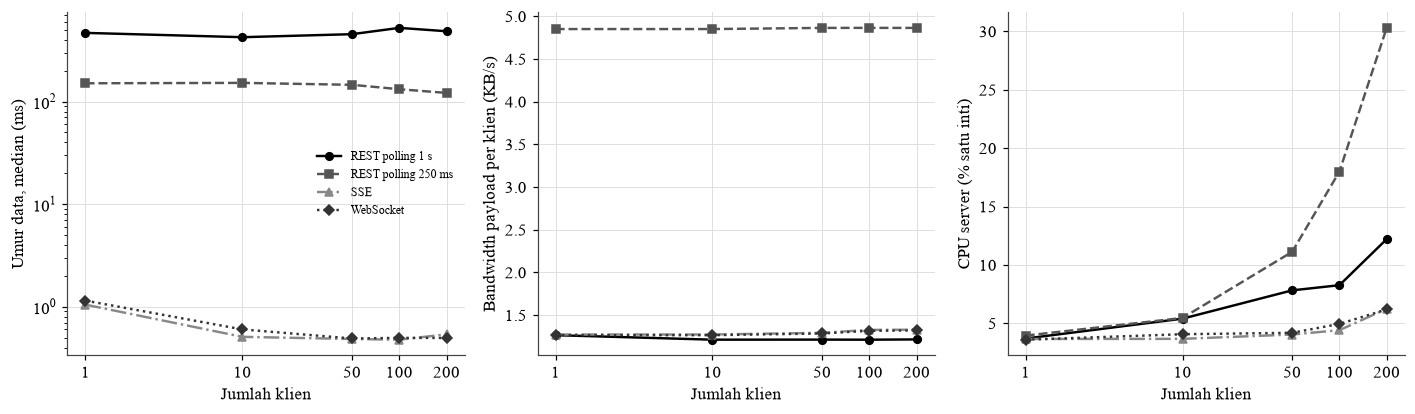

In [4]:
S = pd.read_csv(ROOT/"results/03_transport_ringkasan.csv")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.9))
for col, a, yl in [("umur_median_ms", ax[0], "Umur data, median (ms)"), ("kb_per_klien_s", ax[1], "Bandwidth payload per klien (KB/s)"), ("cpu_server_%", ax[2], "CPU server (% satu inti)")]:
    for lab, st in zip(LABEL.values(), ST):
        s = S[S.konfigurasi == lab].sort_values("klien"); a.plot(s.klien, s[col], label=lab, lw=1.6, ms=5, **st)
    a.set_xscale("log"); a.set_xticks(NS); a.set_xticklabels(NS); a.minorticks_off(); a.set_xlabel("Jumlah klien"); a.set_ylabel(yl)
ax[0].set_yscale("log"); ax[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(ROOT/"grafik/03_transport.png"); plt.show()

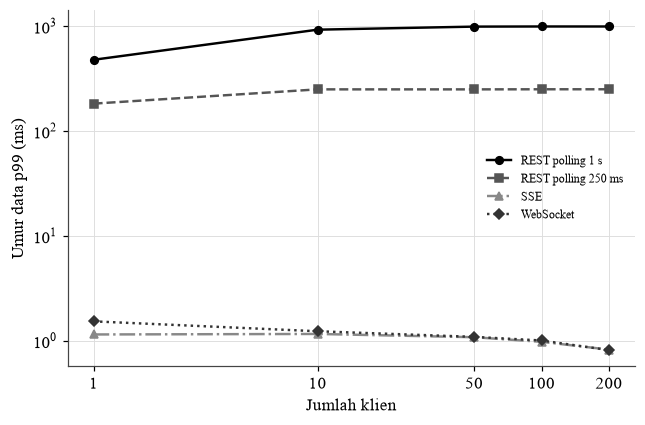

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
for lab, st in zip(LABEL.values(), ST):
    s = S[S.konfigurasi == lab].sort_values("klien"); ax.plot(s.klien, s.p99_ms, label=lab, lw=1.6, ms=5, **st)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(NS); ax.set_xticklabels(NS); ax.minorticks_off()
ax.set_xlabel("Jumlah klien"); ax.set_ylabel("Umur data p99 (ms)"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(ROOT/"grafik/03_transport_p99.png"); plt.show()

## 4. Pembacaan otomatis pada 1 dan 200 klien

In [6]:
for n in (1, 200):
    print(f"--- {n} klien ---")
    for _, r in S[S.klien == n].sort_values("umur_median_ms").iterrows():
        print(f"{r.konfigurasi:20s} umur {r.umur_median_ms:7.1f} ms (p99 {r.p99_ms:7.1f}) | {r.kb_per_klien_s:6.2f} KB/s/klien | CPU server {r['cpu_server_%']:5.1f}%")

--- 1 klien ---
SSE                  umur     1.0 ms (p99     1.1) |   1.27 KB/s/klien | CPU server   3.7%
WebSocket            umur     1.1 ms (p99     1.5) |   1.27 KB/s/klien | CPU server   3.6%
REST polling 250 ms  umur   150.7 ms (p99   182.4) |   4.85 KB/s/klien | CPU server   3.9%
REST polling 1 s     umur   467.4 ms (p99   477.8) |   1.27 KB/s/klien | CPU server   3.7%
--- 200 klien ---
WebSocket            umur     0.5 ms (p99     0.8) |   1.32 KB/s/klien | CPU server   6.2%
SSE                  umur     0.5 ms (p99     0.8) |   1.33 KB/s/klien | CPU server   6.2%
REST polling 250 ms  umur   121.4 ms (p99   250.0) |   4.86 KB/s/klien | CPU server  30.3%
REST polling 1 s     umur   484.9 ms (p99   992.5) |   1.22 KB/s/klien | CPU server  12.2%



## Kesimpulan notebook 03

Dibaca dari tabel di atas (5 ulangan per kombinasi, 12 detik ukur, satu mesin, loopback).

- **Jeda kirim.** SSE dan WebSocket sama: median sekitar 0,5 ms (1 klien: 1 ms), p99 di bawah 1,5 ms sampai 200 klien. Tidak ada selisih yang bisa dipakai untuk memilih di antara keduanya.
- **REST polling 1 detik** punya umur data median 420 sampai 520 ms dan p99 sekitar 990 ms. Itu bukan kelambatan server: klien melihat paket yang sudah menunggu sampai poll berikutnya, jadi nilainya sekitar setengah interval poll. Polling 250 ms menurunkan umur data median menjadi sekitar 120 sampai 150 ms.
- **Bandwidth payload per klien.** Push dan polling 1 detik sama, 1,3 KB/s. Polling 250 ms menjadi 4,9 KB/s karena sekitar 75% respons berisi paket yang sama dengan sebelumnya. Angka ini tidak memasukkan header HTTP. Polling mengirim satu permintaan HTTP per poll, jadi biaya headernya lebih besar daripada yang tampak di sini (TODO: ukur byte jaringan sebenarnya).
- **CPU server** (persen satu inti, termasuk produksi paket sekitar 3,6% sebagai dasar): pada 200 klien, SSE dan WebSocket 6,2%, polling 1 detik 12,2%, polling 250 ms 30,3%. Polling memakai CPU server sekitar dua kali (1 detik) sampai lima kali (250 ms) lipat dibanding push pada 200 klien, karena tiap poll memproses satu permintaan HTTP.
- **Memori server** hanya naik tipis (96 ke 104 MB pada 200 klien push). Tidak membedakan.

**Pembacaan untuk aplikasi.** Untuk grafik live per detik, push (WebSocket atau SSE) memberi jeda terendah dengan biaya server terendah. WebSocket dan SSE setara pada uji ini. SSE lebih sederhana (HTTP biasa, sambung ulang otomatis) tetapi hanya satu arah, sedangkan WebSocket dua arah. TODO: verifikasi sumber untuk perbandingan fitur itu. Polling 1 detik masih layak jika umur data setengah detik dapat diterima dan jumlah klien kecil.

**Keterbatasan yang mengubah cara membaca hasil**
- Satu mesin dan satu jam, loopback tanpa latensi jaringan, kehilangan paket, atau TLS. Jeda 0,5 ms hampir seluruhnya biaya perangkat lunak, bukan jaringan. Di jaringan nyata, jeda push akan didominasi latensi jaringan.
- Klien (4 proses untuk 200 klien) dan server memakai CPU yang sama, jadi pada 200 klien ada persaingan CPU. Selisih CPU server antar protokol tetap terukur, tetapi angka mutlaknya bergantung mesin.
- Pada 1 klien hanya sekitar 11 sampai 12 paket per ulangan, jadi p95/p99 pada 1 klien tidak bermakna, dan interval kepercayaan polling 1 detik pada 1 klien sangat lebar (24 sampai 815 ms) karena fase poll acak.
- Alur MQTT perangkat ke server tidak diuji. Uji dua mesin dengan sinkronisasi NTP tidak dilakukan.
